# Link Prediction in a Stock Correlation Network

- This notebook builds a network of 100 S&P 500 stocks from the correlation of
  their daily log returns, and asks whether the structure of the 2024 network
  predicts which pairs become linked in 2025
- The pedagogical arc:
  - Build the 2024 graph and describe it

In [1]:
!pip install -q networkx==3.7

import networkx as nx

print("networkx version: ", nx.__version__)

networkx version:  3.7


In [2]:
%load_ext autoreload
%autoreload 2

import logging

In [3]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook

import networkx_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpzaoxrbse.json --HistoryManager.hist_file=:memory:


# Part 1: Build the Year One Graph

## Cell 1.1: Load the Cached Data

- `data/` holds the S&P 500 constituents and the adjusted close prices of 100
  of them, written once by `download_data.py`
- See `data/README.md` for the sources, the seed, and the sampling rule

In [4]:
# Load the constituents and the prices of the 100 sampled tickers.
constituents = utils.load_constituents("data")
prices = utils.load_prices("data")

print("constituents.shape=", constituents.shape)
print("prices.shape=", prices.shape)
# Outcome: 503 constituents, and 502 trading days (2024 and 2025) of prices for
# 100 tickers.

constituents.shape= (503, 9)
prices.shape= (502, 100)


## Cell 1.2: Compute the 2024 Daily Log Returns

- The log return of day $t$ is $r_t = \log(P_t / P_{t-1})$
- Returns are computed within 2024 only, so the first trading day of the year
  has no return

In [5]:
# Compute the daily log returns of the first year.
returns_2024 = utils.compute_log_returns(prices, 2024)

print("returns_2024.shape=", returns_2024.shape)
# Outcome: 251 daily returns, one fewer than the 252 trading days of 2024.

returns_2024.shape= (251, 100)


## Cell 1.3: Compute the Correlation Matrix

In [6]:
# Compute the Pearson correlation of every pair of tickers.
corr_2024 = utils.compute_correlation(returns_2024)

display(corr_2024.iloc[:5, :5].round(2))
# Outcome: a 100 x 100 symmetric matrix with ones on the diagonal; most pairs
# are weakly positive.

,AKAM,AME,AMP,AOS,APA
AKAM,1.00,0.16,0.19,0.22,0.14
AME,0.16,1.00,0.39,0.36,0.23
AMP,0.19,0.39,1.00,0.22,0.32
AOS,0.22,0.36,0.22,1.00,0.14
APA,0.14,0.23,0.32,0.14,1.00


## Cell 1.4: Link the Top 10% of Pairs

- 100 tickers give $100 \cdot 99 / 2 = 4950$ pairs
- The 495 pairs with the highest correlation become edges
  - Ties are broken by ticker name, so the graph is the same on every run
- Every ticker is a node with its GICS sector as the `sector` attribute, even if
  it has no edge

In [7]:
# Map each ticker to its GICS sector.
sectors = constituents.set_index("Symbol")["GICS Sector"]
# Link the 10% of the pairs with the highest correlation.
graph_2024 = utils.build_correlation_graph(corr_2024, sectors, 0.1)

print("graph_2024=", graph_2024)
print("threshold=", round(graph_2024.graph["threshold"], 4))
# Outcome: 100 nodes and 495 edges; every linked pair has a correlation of at
# least the printed threshold.

graph_2024= Graph with 100 nodes and 495 edges
threshold= 0.3701


## Cell 1.5: Report the Graph Statistics

In [8]:
# Summarize the size, density, and degree distribution of the graph.
stats_2024 = utils.compute_graph_stats(graph_2024)

display(stats_2024)
# Outcome: density 0.1, a median degree below the mean, 11 isolated tickers,
# and one large component.

,value
nodes,100
edges,495
density,0.1
correlation threshold,0.3701
min degree,0
median degree,6.0
mean degree,9.9
max degree,35
isolated nodes,11
connected components,13


- The density is 0.10 by construction, not a finding
  - Linking the top 10% of pairs fixes 495 edges out of 4950 possible pairs
  - The edge count and the mean degree are fixed the same way
- The degree distribution is the informative statistic
  - The median degree is below the mean, so a few tickers hold many of the
    edges while many tickers have one or none
  - Isolated tickers have no pair in the top 10%, so link prediction scores
    based on shared neighbors are zero for every pair that involves them

## Cell 1.6: Plot the Degree Distribution

**Goal**
- See how the 495 edges are spread across the 100 tickers

**Description**
- Inputs
  - `graph_2024`: the 2024 correlation graph from Cell 1.4

- Panels
  - `Degree distribution`: number of tickers for each degree, with the mean and
    median degree as vertical lines and the three highest-degree tickers in
    the title

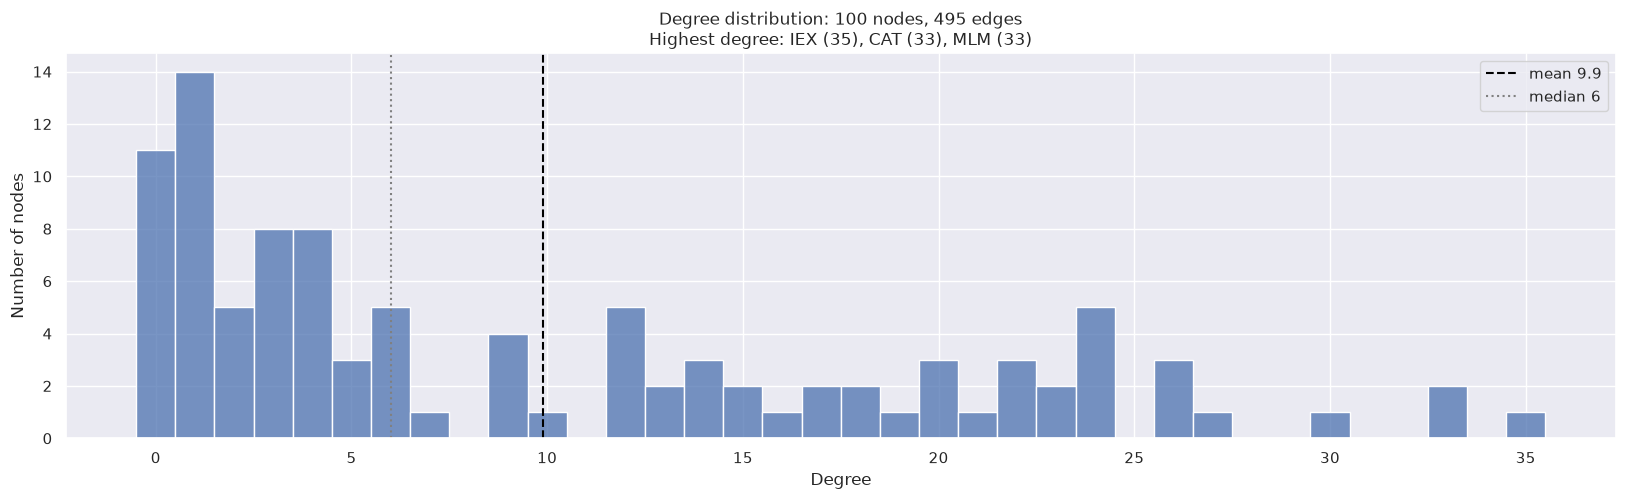

In [9]:
# Plot the number of tickers for each degree.
utils.plot_degree_histogram(graph_2024)

**Guided usage**
- Compare the bars at degree 0 and 1 with the long tail to the right
  - Observe about a quarter of the tickers with at most one edge, while about
    a fifth have 20 or more
- Compare the `median` line with the `mean` line
  - Observe the median sit well left of the mean, the sign of a right-skewed
    distribution
- Read the tickers named in the title
  - Observe that the three highest-degree tickers are two industrial companies
    and one materials company

**Implementation** `plot_degree_histogram(graph, figsize=None)`
- Reads the degree of every node with `graph.degree()`
- Draws one bar per degree value with `seaborn.histplot(discrete=True)`
- Adds the mean and median degree as vertical lines, and names the three
  highest-degree tickers in the title

In [10]:
hintros.print_obj_info(utils.plot_degree_histogram)

- `plot_degree_histogram(graph: networkx.classes.graph.Graph, *, figsize: Optional[Tuple[int, int]] = None) -> None`  
  Plot the number of nodes for each degree value.

https://github.com/umdHSacks/gpsaggese.github.io/blob/UmdTask959_DATA605_Fall2026_NetworkX_Link_Prediction_in_a_Stock_Correlation_Network/class_project/data605/Fall2026/projects/UmdTask959_DATA605_Fall2026_NetworkX_Link_Prediction_in_a_Stock_Correlation_Network/networkx_utils.py#L204
